# 04 · Supervised Classification — FinSight AI
**Phase 5 · Subject: ML** (DT / NB / KNN are also DMW's classification component) · KDD steps 5–6

| RQ | Question |
|---|---|
| **RQ3** | Do behavioural (Exp B) and network (Exp C) features measurably improve classification over raw transaction features (Exp A), and only where real network structure exists (v1.0 vs v1.1)? |
| **RQ4** | Which classifier performs best? Does SMOTE beat class weighting? |
| **RQ7** | Which fraud scenarios, and which BORDERLINE cases, are hardest? |

### Protocol (Plan §7.1; leakage-safe by construction)
| Item | Choice |
|---|---|
| Target | `is_fraud` (BORDERLINE = 0, analysed separately) |
| Features | Exp A 12 · Exp B 30 · Exp C 49 columns; blacklist enforced in `feature_sets.get_xy` (tested) |
| Split | stratified 60/20/20 on `risk_label` → train 6,000 / val 2,000 / test 2,000 |
| Model comparison | **5×2 repeated stratified CV** on the 80% dev set, with identical folds for every config, so comparisons are *paired* (t-test + Wilcoxon) |
| Imbalance | SMOTE **inside** the imblearn pipeline (re-fit per fold); compared against class weighting and none |
| Threshold | max-F1 on validation, never on test |
| Test | scored **once** per configuration |
| Robustness | temporal hold-out: train Aug 1–19 / val 20–23 / test 24–30 |

Hyperparameters are sensible defaults; tuning is Phase 7. Results come from `make pipeline STAGES=train_supervised` (~6 min, 8 cores); this notebook loads them and reloads the saved models.

In [1]:
import warnings, json; warnings.filterwarnings("ignore")
import joblib, numpy as np, pandas as pd
from IPython.display import display
from finsight import viz, config
from finsight.eda import load_master
from finsight.ml import supervised as S, supervised_figures as F
from finsight.ml.classifiers import MODELS, MODEL_LABELS
from finsight.ml.feature_sets import get_xy, feature_columns
from finsight.ml.splits import stratified_split
viz.apply_style()
pd.set_option("display.width", 200, "display.max_columns", 30)
R = config.REPORTS_DIR
results = pd.read_csv(R / "ml_experiment_results.csv")
cv = pd.read_csv(R / "ml_cv_folds.csv")
sig = pd.read_csv(R / "ml_paired_tests.csv")
summary = json.loads((R / "ml_summary.json").read_text())
print({e: len(feature_columns(e)) for e in "ABC"}, summary["split_sizes"])

{'A': 12, 'B': 30, 'C': 49} {'train': 6000, 'val': 2000, 'test': 2000}


## 1 · RQ3: does each feature group help? (5×2 CV, paired)

version         v1_0          v1_1       
comparison    B vs A C vs B B vs A C vs B
model                                    
decision_tree  0.138  0.006  0.069  0.014
knn            0.289 -0.011  0.102  0.084
mlp            0.224 -0.009  0.106  0.072
naive_bayes    0.380 -0.011  0.087  0.088
random_forest  0.195 -0.002  0.090  0.054
xgboost        0.197 -0.005  0.106  0.047

version          v1_0            v1_1        
comparison     B vs A  C vs B  B vs A  C vs B
model                                        
decision_tree  0.0000  0.4486  0.0000  0.1941
knn            0.0000  0.2223  0.0000  0.0000
mlp            0.0000  0.4381  0.0000  0.0000
naive_bayes    0.0000  0.0976  0.0010  0.0000
random_forest  0.0000  0.2841  0.0000  0.0000
xgboost        0.0000  0.0539  0.0000  0.0000

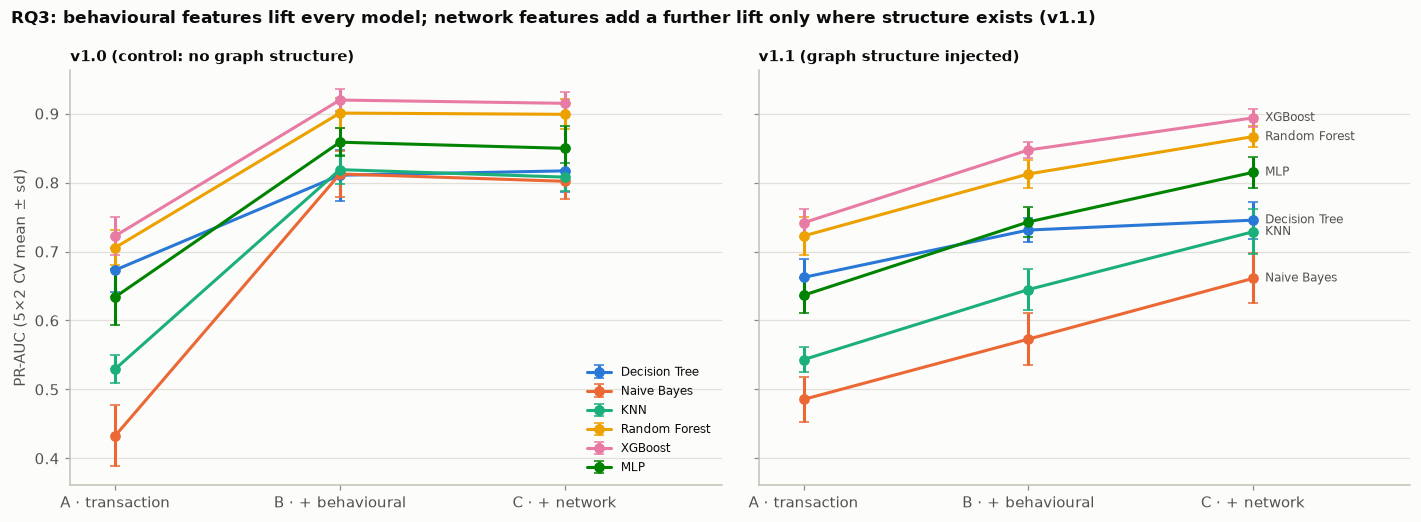

In [2]:
F.fig_abc_lines(results);
display(sig.pivot_table(index="model", columns=["version", "comparison"], values="mean_diff").round(3))
display(sig.pivot_table(index="model", columns=["version", "comparison"], values="t_pvalue").map(lambda p: f"{p:.4f}"))

| Comparison | v1.0 (no graph structure, control) | v1.1 (structure injected) |
|---|---|---|
| **B vs A** (+ behavioural) | significant for **6/6** models, +0.14 to +0.38 PR-AUC | significant for **6/6**, +0.07 to +0.11 |
| **C vs B** (+ network) | **0/6 significant** (Δ −0.011 to +0.006) | **5/6 significant** (+0.05 to +0.09, p < 0.001, 10/10 fold wins); Decision Tree not significant |

**Answer to RQ3:** behavioural context is the biggest single gain. Network features give a further, statistically significant gain **only when real network structure exists**. On v1.0 they add nothing, which is exactly what the control predicts. The single-feature AUCs from Phase 2 (≤ 0.64) understated them: their value is in *combination* with behaviour.

Note: v1.1 B-level scores are *lower* than v1.0's because 50% of organised fraud was behaviourally camouflaged (D-002). Without network features that fraud is hard; with them, most of the gap closes.

## 2 · RQ4: which model wins? (held-out test)

,model,exp,cv_pr_auc_mean,cv_pr_auc_std,test_pr_auc,test_roc_auc,test_f1,test_precision,test_recall,test_threshold
32,xgboost,C,0.894,0.014,0.875,0.980,0.801,0.698,0.941,0.096
29,random_forest,C,0.867,0.015,0.838,0.976,0.799,0.750,0.856,0.485
31,xgboost,B,0.847,0.012,0.829,0.974,0.783,0.704,0.881,0.190
35,mlp,C,0.815,0.023,0.798,0.962,0.734,0.717,0.752,0.518
28,random_forest,B,0.812,0.021,0.766,0.969,0.780,0.700,0.881,0.367
26,knn,C,0.729,0.033,0.709,0.935,0.707,0.654,0.770,0.788
30,xgboost,A,0.742,0.020,0.690,0.949,0.677,0.585,0.804,0.181
20,decision_tree,C,0.745,0.027,0.690,0.946,0.787,0.693,0.911,0.268
34,mlp,B,0.743,0.021,0.681,0.942,0.663,0.596,0.748,0.191
19,decision_tree,B,0.731,0.017,0.671,0.934,0.738,0.643,0.867,0.255


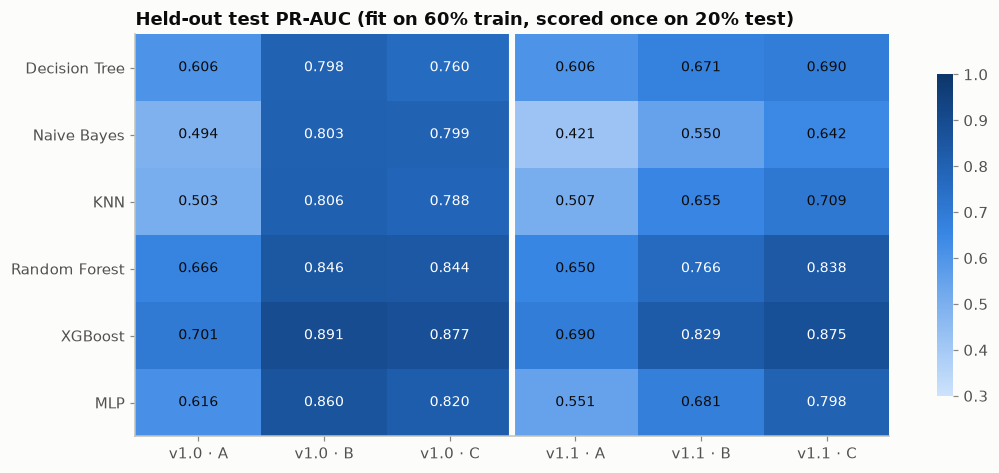

In [3]:
F.fig_test_heatmap(results);
cols = ["model", "exp", "cv_pr_auc_mean", "cv_pr_auc_std", "test_pr_auc", "test_roc_auc", "test_f1", "test_precision", "test_recall", "test_threshold"]
display(results.query("version == 'v1_1'")[cols].sort_values("test_pr_auc", ascending=False).round(3))

**Ranking on v1.1 Exp C (test PR-AUC):** XGBoost **0.875** > Random Forest 0.838 > MLP 0.798 > KNN 0.709 > Decision Tree 0.690 > Naive Bayes 0.642. CV means rank the models identically, so the ranking isn't test-set luck.
- **Boosting and bagging ensembles** dominate: they capture feature interactions (e.g. *large amount × recent beneficiary × quick inflow*).
- **Naive Bayes** suffers most from its independence assumption: amount and amount ratio are strongly correlated (ρ = 0.85, Phase 2).
- **Naive Bayes and KNN** gain the most from B to C (+0.09, +0.08). Network features make camouflaged fraud *close* to other fraud in feature space.

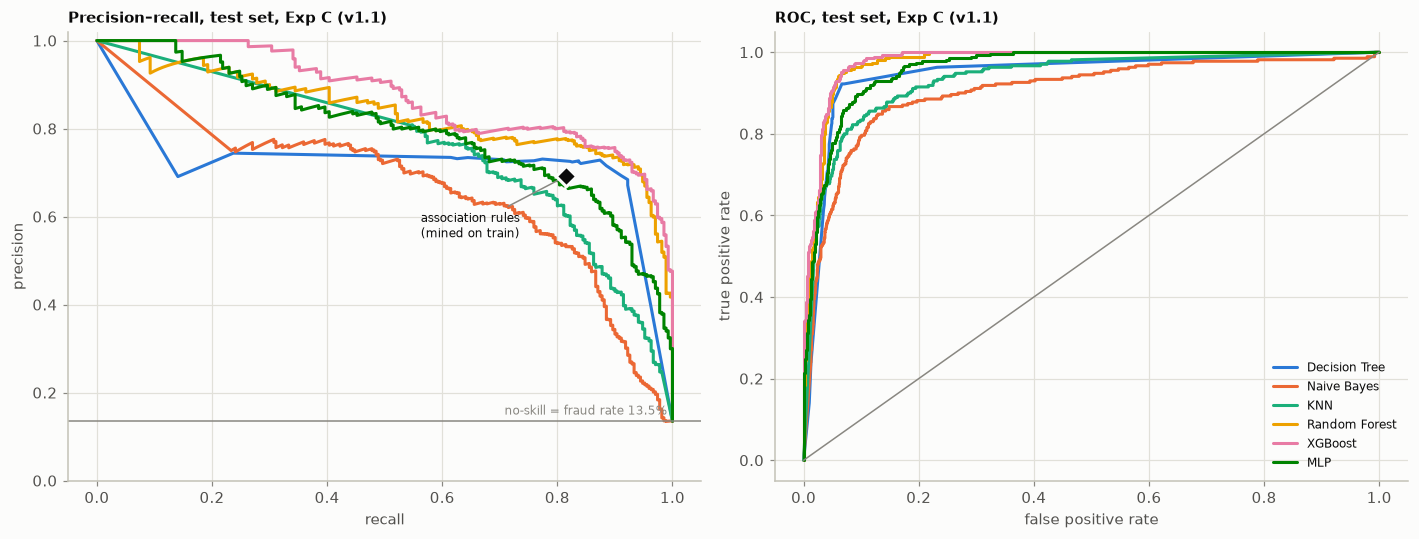

In [4]:
m11 = load_master("v1_1"); sp = stratified_split(m11)
y_test = m11["is_fraud"].to_numpy()[sp.test]
curves = {}
for n in MODELS:                                       # reload persisted models (Phase 5 artifacts)
    model = joblib.load(config.ARTIFACTS_DIR / "models" / "phase5" / f"{n}_expC_v1_1.joblib")
    X, _ = get_xy(m11, "C")
    curves[(n, "C")] = model.predict_proba(X.iloc[sp.test])[:, 1]
F.fig_pr_roc(curves, y_test, "C", summary["rule_baseline_v1_1"]["test"]);

ROC-AUC is ≥ 0.90 for every model (0.904–0.980); **ROC hides the differences that PR-AUC shows**, because with 13.5% positives a small false-positive *rate* is still many false alarms. This is why PR-AUC is the primary metric.

**Association rules vs ML (Phase 4 carry-over, now held-out):** rules re-mined on the *training* split, with k chosen on validation (36 rules), score test **F1 0.75 (precision 0.69, recall 0.81), PR-AUC 0.78**. That's competitive with the single tree and close to MLP, but below the ensembles (XGBoost F1 0.80, recall 0.94). Rules trade some accuracy for full transparency.

## 3 · Imbalance: SMOTE vs class weights vs nothing

,model,imbalance,pr_auc_mean,pr_auc_std,f1_at_0.5_mean,f1_at_0.5_std
0,decision_tree,class_weight,0.802,0.022,0.808,0.014
1,decision_tree,none,0.795,0.030,0.784,0.020
2,decision_tree,smote,0.745,0.027,0.799,0.015
3,knn,none,0.790,0.031,0.663,0.041
4,knn,smote,0.729,0.033,0.641,0.022
5,mlp,none,0.856,0.021,0.768,0.021
6,mlp,smote,0.815,0.023,0.739,0.016
7,naive_bayes,none,0.667,0.036,0.479,0.047
8,naive_bayes,smote,0.661,0.036,0.501,0.051
9,random_forest,class_weight,0.880,0.016,0.836,0.004


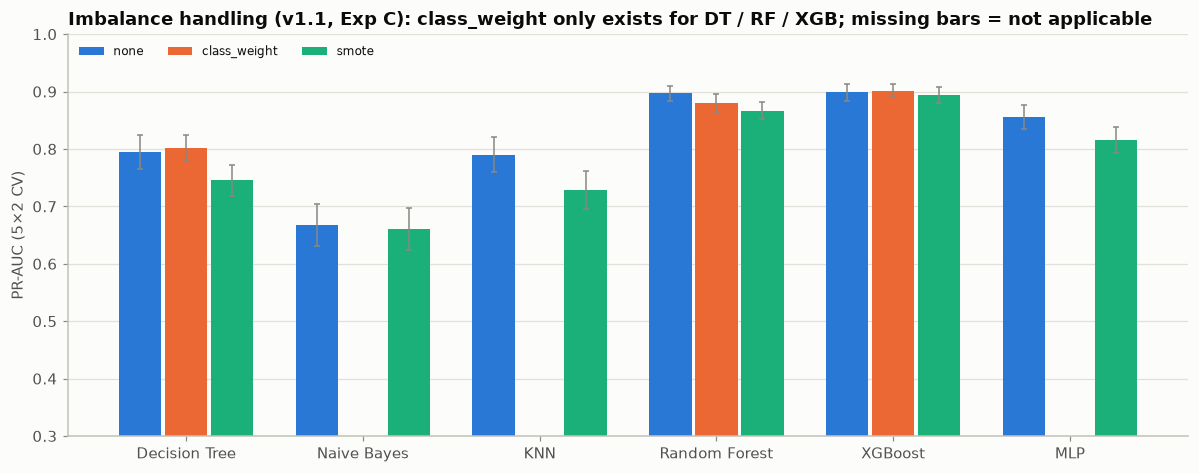

In [5]:
F.fig_imbalance(cv);
display(pd.read_csv(R / "ml_imbalance.csv").round(3))

**SMOTE never improved PR-AUC** and was slightly worse for most models (DT 0.745 vs 0.802 with class_weight; KNN 0.729 vs 0.790 with none; MLP 0.815 vs 0.856). Reasons:
1. PR-AUC is threshold-free, and we tune the threshold on validation anyway, so rebalancing mostly shifts scores rather than adding information.
2. SMOTE interpolates between minority points, including across one-hot categoricals and across *different* fraud scenarios, creating unrealistic synthetic fraud.

For tree ensembles, class weighting ≈ none ≈ SMOTE (within one standard deviation). **Decision for Phase 7 (D-020): tune with `class_weight` for DT/RF/XGB and no resampling for KNN/MLP/NB, with validation-tuned thresholds.** SMOTE stays in the report as the plan's baseline, a negative result worth stating.

## 4 · RQ7: which scenarios are hardest?

exp,A,B,C
scenario,,,
S10 impossible travel,0.875,1.000,1.000
S11 shared device ip,1.000,0.952,1.000
S2 high value spike,0.500,0.750,0.800
S3 rapid burst,0.278,0.833,0.889
S4 new beneficiary large tx,0.632,0.947,0.947
S5 new device suspicious,0.958,1.000,1.000
S6 structuring splitting,1.000,1.000,0.957
S7 layering network,0.667,0.646,0.854
S8 mule pass through,0.900,0.900,0.975


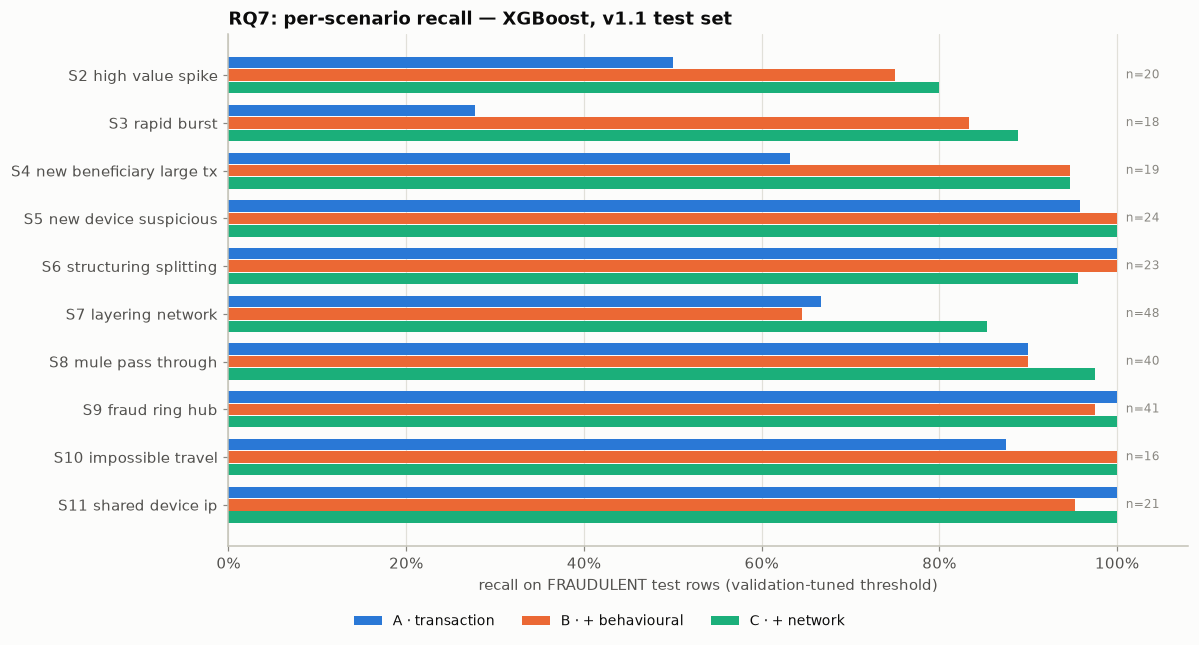

In [6]:
scen = pd.read_csv(R / "ml_per_scenario.csv")
F.fig_per_scenario(scen, "xgboost")
display(scen.query("model == 'xgboost' and risk_label == 'FRAUDULENT'").pivot(index="scenario", columns="exp", values="flag_rate").round(3))

XGBoost test recall by scenario (n = 16–48 fraud rows each, so treat ±10 points as noise):
- **Network features fix the network scenarios:** S7 layering **65% → 85%** (B → C), S8 mule 90% → 97.5%, S3 burst 83% → 89%. These are exactly the camouflaged organised-fraud scenarios.
- **Hardest overall: S2 high-value spike (80%)**. Its only signal is the amount, and legitimate RTGS payments are large too (Phase 2).
- S5, S9, S10, S11 reach ~100% even without network features (strong behavioural or location fingerprints).

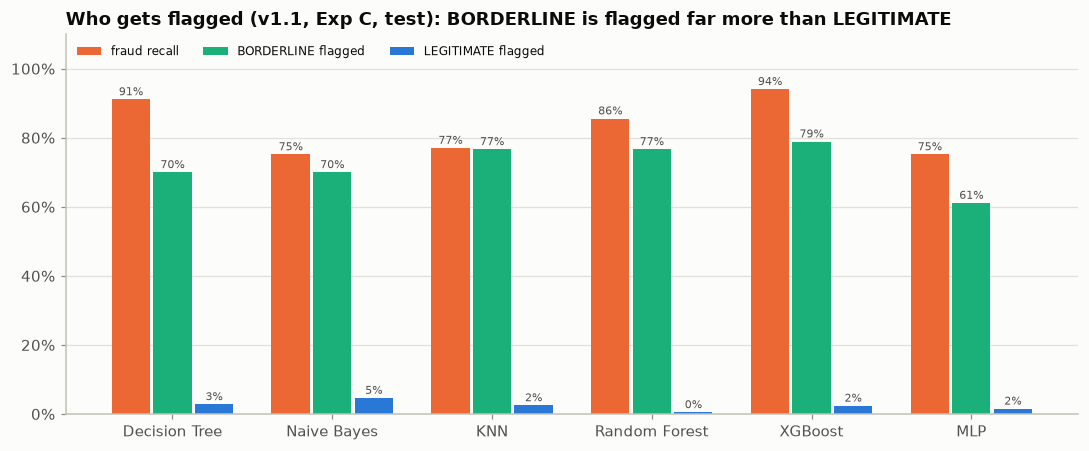

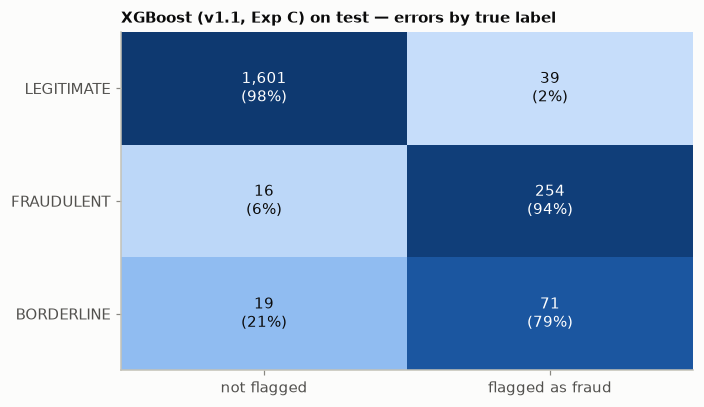

In [7]:
F.fig_borderline(results)
F.fig_confusion_by_label(m11.iloc[sp.test], curves[("xgboost", "C")],
                         float(results.query("version=='v1_1' and model=='xgboost' and exp=='C'").test_threshold.iloc[0]), "xgboost");

**BORDERLINE is the dominant error source:** XGBoost flags only **2% of legitimate** test rows but **79% of BORDERLINE** rows. **71 of its 110 false positives (65%) are BORDERLINE**: transactions whose features look like fraud but were labelled non-fraud. Every model shows the same pattern (61–79% of BORDERLINE flagged vs 0–5% of LEGITIMATE).

In practice these are exactly the cases a bank would want *reviewed*, not ignored. The 3-class extension below quantifies how separable they are.

In [8]:
tri = summary["three_class_xgb_expC"]
print("macro-F1:", tri["macro_f1"], "| per-class F1:", tri["per_class_f1"])
display(pd.DataFrame(tri["confusion"], index=[f"true {l}" for l in tri["labels"]], columns=[f"pred {l}" for l in tri["labels"]]))

macro-F1: 0.7896 | per-class F1: {'LEGITIMATE': 0.9903, 'FRAUDULENT': 0.8231, 'BORDERLINE': 0.5556}


,pred LEGITIMATE,pred FRAUDULENT,pred BORDERLINE
true LEGITIMATE,1626,14,0
true FRAUDULENT,15,228,27
true BORDERLINE,3,42,45


**3-class extension (XGBoost, Exp C, class-balanced):** LEGITIMATE F1 0.99, FRAUDULENT 0.82, **BORDERLINE 0.56**. Borderline is half-separable: 45 of 90 are recognised as borderline, 42 are called fraud. The labels are partly ambiguous by construction. A production system should treat BORDERLINE as its own "review" tier (the plan's MEDIUM/HIGH risk tiers, Phase 7).

## 5 · Temporal robustness

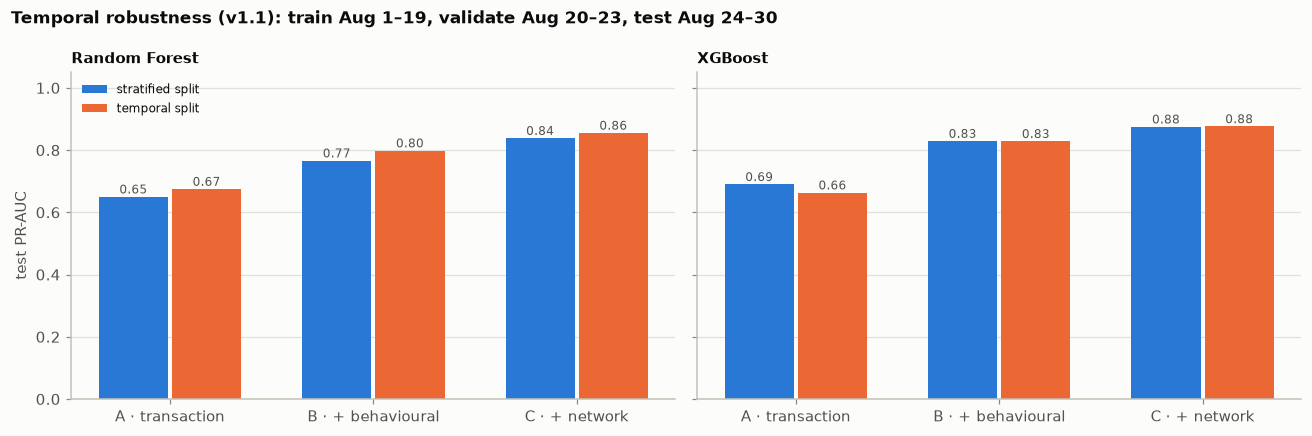

In [9]:
F.fig_temporal(pd.read_csv(R / "ml_temporal.csv"));

Training on Aug 1–19 and testing on Aug 24–30 gives the same picture: XGBoost C **0.876** (temporal) vs 0.875 (stratified), and the A < B < C ordering holds. There's no temporal drift within the month, so the random split isn't flattering the models. (One month of synthetic data can't test seasonal drift; that's a stated limitation.)

## 6 · An interpretable model: the depth-4 decision tree

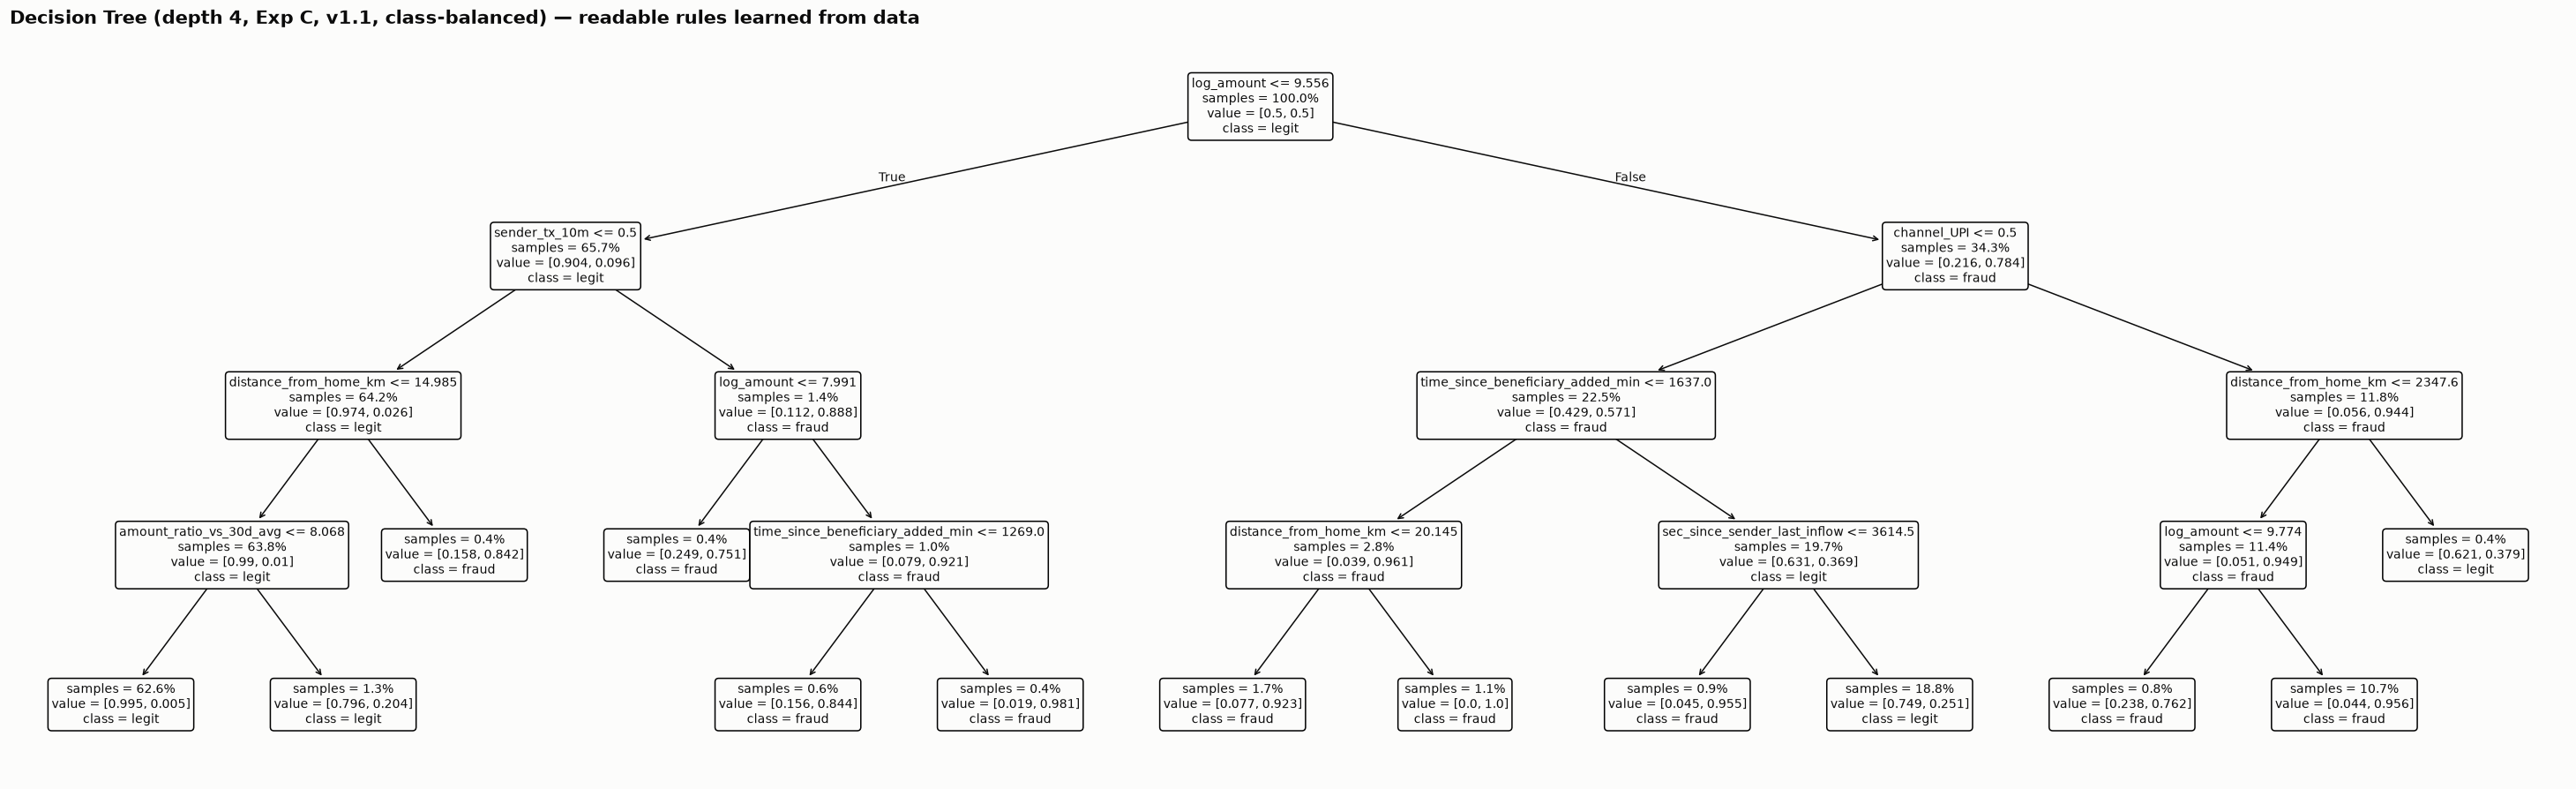

In [10]:
tree, feats = S.decision_tree_for_plot(m11, sp)
F.fig_tree(tree, feats);

The shallow tree (class-balanced, Exp C) reads like an analyst's checklist:
1. **Amount** (log ≤ 9.56 ≈ ₹14,000) is the first split.
2. Small payments are risky only when the **sender is bursting** (`sender_tx_10m` > 0, network) or **far from home**.
3. Large non-UPI payments are risky when the **beneficiary is new** (< ~27 h) or money **arrived < 1 h before** (`sec_since_sender_last_inflow`, network).

Network features appear at depths 1 and 3, matching the association rules from Phase 4 (QUICK_INFLOW, BURST_SENDER).

## 7 · Summary

| RQ | Answer |
|---|---|
| **RQ3** | B > A for every model and version (p < 0.001). C > B **only on v1.1** (5/6 models, +0.05 to +0.09 PR-AUC, p < 0.001); on v1.0, C = B. Network features help exactly where network structure exists. |
| **RQ4** | **XGBoost (Exp C): test PR-AUC 0.875, ROC-AUC 0.980, F1 0.801, precision 0.70, recall 0.94**, then RF 0.838 and MLP 0.798. SMOTE never helped; class weighting or none plus a tuned threshold is as good or better. |
| **RQ7** | Hardest: S2 high-value spike (80%) and S7 layering without network features (65% → 85% with them). BORDERLINE causes 65% of false positives; as a separate class it reaches only F1 0.56. |

| Baselines on the same test set | PR-AUC | F1 |
|---|---|---|
| Association rules (train-mined, k on val) | 0.779 | 0.748 |
| XGBoost Exp A (transaction only) | 0.690 | 0.677 |
| **XGBoost Exp C** | **0.875** | **0.801** |

**Hand-off to Phase 7:** tune XGBoost/RF/MLP (Grid/Randomized, 5-fold), use class_weight/no-resampling (D-020), stack RF + XGB + MLP, calibrate, choose risk tiers on validation. The current best (0.875) is the bar to beat.

**Outputs:** `reports/ml_experiment_results.csv`, `ml_cv_folds.csv`, `ml_paired_tests.csv`, `ml_imbalance.csv`, `ml_per_scenario.csv`, `ml_temporal.csv`, `ml_summary.json`, `figures/ml_01…09`; models `artifacts/models/phase5/*_expC_v1_1.joblib`.